In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist


In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print((X_train.shape, y_train.shape), (X_test.shape, y_test.shape))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
((60000, 28, 28), (60000,)) ((10000, 28, 28), (10000,))


In [6]:
import matplotlib.pyplot as plt

In [12]:
y_train.data[0]

5

In [19]:
import random

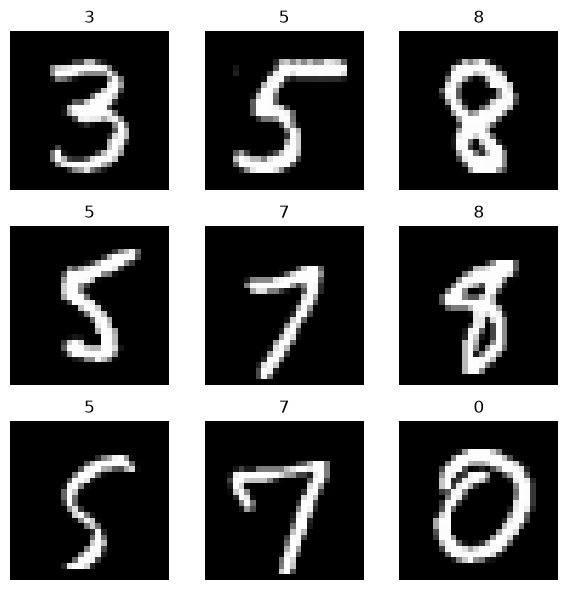

In [77]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for ax in axes.flatten():
    rand_value = random.randint(0, len(X_train))
    ax.imshow(X_train[rand_value], cmap='gray')
    ax.set_title(y_train.data[rand_value])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [85]:
X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255
X_test = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255

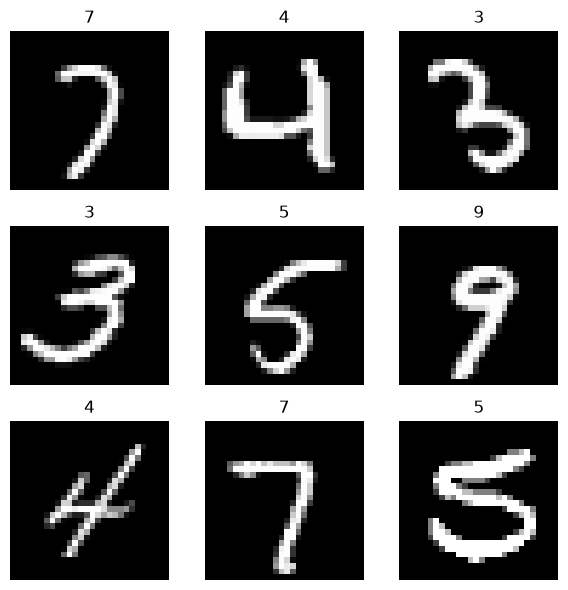

In [86]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for ax in axes.flatten():
    rand_value = random.randint(0, len(X_train))
    ax.imshow(X_train[rand_value], cmap='gray')
    ax.set_title(y_train.data[rand_value])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [90]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [94]:
model.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9838 - loss: 0.0543 - val_accuracy: 0.9874 - val_loss: 0.0376
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9887 - loss: 0.0388 - val_accuracy: 0.9881 - val_loss: 0.0360
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9909 - loss: 0.0291 - val_accuracy: 0.9887 - val_loss: 0.0353
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9923 - loss: 0.0238 - val_accuracy: 0.9892 - val_loss: 0.0337
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9942 - loss: 0.0176 - val_accuracy: 0.9895 - val_loss: 0.0338
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9950 - loss: 0.0153 - val_accuracy: 0.9886 - val_loss: 0.0404
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9959 - loss: 0.0124 - val_accuracy: 0.9910 - val_loss: 0.0287
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9969 - loss: 0.0090 - val_accuracy: 0.

In [105]:
predicted = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [110]:
import numpy as np

7

In [153]:
def plot_prediction():
    rand_value = random.randint(0, len(X_test))
    predicted = model.predict(X_test)

    value = np.argmax(predicted[rand_value]).item()

    plt.imshow(X_test[rand_value], cmap='gray')
    plt.title(f"Original : {y_test.data[rand_value]} | Predicted : {value}")
    plt.axis('off')
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


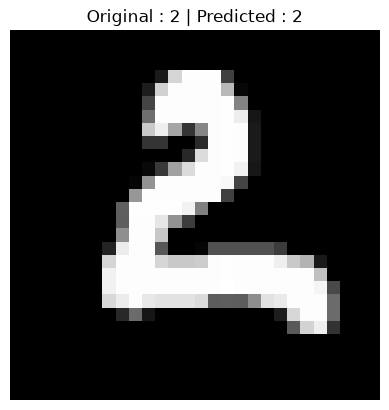

In [169]:
plot_prediction()